# Machine learning CA1
**Module Title** : Machine learning
    
**Assessment Title** : Machine learning-HDip CA1

**Dataset** : Irish Building Energy Ratings (BER) Dataset

**Student ID** : 2026545

**Student Name** : Ankhjargal Tsogtjargal

## 1. Data Loading and Exploration

This project uses the Irish Building Energy Ratings (BER) dataset to predict the energy efficiency of buildings.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_excel("BERPublicsearch.xlsx", nrows=10000)

In [3]:
df.head()

,CountyName,DwellingTypeDescr,Year_of_Construction,TypeofRating,EnergyRating,BerRating,GroundFloorArea(sq m),UValueWall,UValueRoof,UValueFloor,...,CPC,EPC,Unnamed: 192,IsSolarPVBatteryPresent,SolarBatteryCapacity,SolarPVEnergyOutput,WindTurbineEnergyOutput,FirstWindTurbineRotorDiameter,FirstWindTurbineHubHeight,FirstWindTurbineTerrainType
0,Co. Clare,House,2009,Provisional,B1,80.29,278.03,0.16,0.16,0.15,...,0.684,0.582,NaN,0,0,0,0,NaN,NaN,NaN
1,Co. Meath,Mid-terrace house,1960,Existing,B3,141.47,86.28,0.29,0.20,0.43,...,NaN,NaN,NaN,0,0,0,0,NaN,NaN,NaN
2,Co. Cork,Detached house,1898,Existing,G,853.33,44.55,1.99,2.30,1.02,...,NaN,NaN,NaN,0,0,0,0,NaN,NaN,NaN
3,Co. Wexford,Mid-floor apartment,2007,Final,B2,118.22,88.00,0.25,0.00,0.00,...,NaN,NaN,NaN,0,0,0,0,NaN,NaN,NaN
4,Co. Dublin,Mid-floor apartment,2008,Existing,C2,197.14,74.98,0.34,0.00,1.00,...,NaN,NaN,NaN,0,0,0,0,NaN,NaN,NaN


In [4]:
df.shape

(10000, 200)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Columns: 200 entries, CountyName to FirstWindTurbineTerrainType
dtypes: float64(132), int64(18), object(50)
memory usage: 15.3+ MB


In [6]:
df.isnull().sum()

CountyName                           0
DwellingTypeDescr                    0
Year_of_Construction                 0
TypeofRating                         0
EnergyRating                         0
                                 ...  
SolarPVEnergyOutput                  0
WindTurbineEnergyOutput              0
FirstWindTurbineRotorDiameter    10000
FirstWindTurbineHubHeight        10000
FirstWindTurbineTerrainType      10000
Length: 200, dtype: int64

In [7]:
df.describe()

,Year_of_Construction,BerRating,GroundFloorArea(sq m),UValueWall,UValueRoof,UValueFloor,UValueWindow,UvalueDoor,WallArea,RoofArea,...,CPC,EPC,Unnamed: 192,IsSolarPVBatteryPresent,SolarBatteryCapacity,SolarPVEnergyOutput,WindTurbineEnergyOutput,FirstWindTurbineRotorDiameter,FirstWindTurbineHubHeight,FirstWindTurbineTerrainType
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,...,238.000000,238.000000,0.0,10000.0,10000.0,10000.0,10000.00000,0.0,0.0,0.0
mean,1991.152800,238.525424,103.845020,0.608704,0.331924,0.314348,2.447984,2.458855,82.268033,54.771641,...,0.799408,0.781277,NaN,0.0,0.0,0.0,0.22310,NaN,NaN,NaN
std,32.459319,304.809762,57.055688,0.532021,0.498642,0.251003,0.918284,0.980192,56.462778,46.660442,...,0.284655,0.253550,NaN,0.0,0.0,0.0,19.13251,NaN,NaN,NaN
min,1753.000000,19.520000,5.470000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.158000,0.392000,NaN,0.0,0.0,0.0,0.00000,NaN,NaN,NaN
25%,1994.000000,131.930000,71.000000,0.270000,0.130000,0.170000,1.700000,2.200000,41.660000,29.790000,...,0.645000,0.598000,NaN,0.0,0.0,0.0,0.00000,NaN,NaN,NaN
50%,2005.000000,185.275000,92.150000,0.370000,0.200000,0.260000,2.500000,3.000000,75.630000,50.500000,...,0.744000,0.755500,NaN,0.0,0.0,0.0,0.00000,NaN,NaN,NaN
75%,2008.000000,284.335000,118.017500,0.550000,0.350000,0.440000,2.800000,3.000000,104.000000,69.607500,...,0.887500,0.877750,NaN,0.0,0.0,0.0,0.00000,NaN,NaN,NaN
max,2010.000000,21725.620000,813.840000,3.580000,2.300000,1.720000,6.000000,6.910000,650.810000,522.350000,...,2.811000,3.019000,NaN,0.0,0.0,0.0,1881.00000,NaN,NaN,NaN


In [8]:
df["EnergyRating"].value_counts()

EnergyRating
B3    1580
B2    1386
C1    1029
C2     797
D1     791
D2     779
C3     749
G      702
B1     547
E1     524
F      472
E2     466
A3     172
A2       5
A1       1
Name: count, dtype: int64

In [9]:
missing_percent = df.isnull().mean() * 100

print("100% missing columns:",(missing_percent == 100).sum())

print("Columns with less than 20% missing:",(missing_percent < 20).sum())

100% missing columns: 19
Columns with less than 20% missing: 130


In [10]:
df.columns.tolist()

['CountyName',
 'DwellingTypeDescr',
 'Year_of_Construction',
 'TypeofRating',
 'EnergyRating',
 'BerRating',
 'GroundFloorArea(sq m)',
 'UValueWall',
 'UValueRoof',
 'UValueFloor',
 'UValueWindow',
 'UvalueDoor',
 'WallArea',
 'RoofArea',
 'FloorArea',
 'WindowArea',
 'DoorArea',
 'NoStoreys',
 'CO2Rating',
 'MainSpaceHeatingFuel',
 'MainWaterHeatingFuel',
 'HSMainSystemEfficiency',
 'MultiDwellingMPRN',
 'TGDLEdition',
 'MPCDERValue',
 'HSEffAdjFactor',
 'HSSupplHeatFraction',
 'HSSupplSystemEff',
 'WHMainSystemEff',
 'WHEffAdjFactor',
 'SupplSHFuel',
 'SupplWHFuel',
 'SHRenewableResources',
 'WHRenewableResources',
 'NoOfChimneys',
 'NoOfOpenFlues',
 'NoOfFansAndVents',
 'NoOfFluelessGasFires',
 'DraftLobby',
 'VentilationMethod',
 'FanPowerManuDeclaredValue',
 'HeatExchangerEff',
 'StructureType',
 'SuspendedWoodenFloor',
 'PercentageDraughtStripped',
 'NoOfSidesSheltered',
 'PermeabilityTest',
 'PermeabilityTestResult',
 'TempAdjustment',
 'HeatSystemControlCat',
 'HeatSystemRespo

In [11]:
usable_columns = missing_percent[missing_percent < 20].index.tolist()

print("Usable columns:", len(usable_columns))
print(usable_columns)

Usable columns: 130
['CountyName', 'DwellingTypeDescr', 'Year_of_Construction', 'TypeofRating', 'EnergyRating', 'BerRating', 'GroundFloorArea(sq m)', 'UValueWall', 'UValueRoof', 'UValueFloor', 'UValueWindow', 'UvalueDoor', 'WallArea', 'RoofArea', 'FloorArea', 'WindowArea', 'DoorArea', 'NoStoreys', 'CO2Rating', 'MainSpaceHeatingFuel', 'MainWaterHeatingFuel', 'HSMainSystemEfficiency', 'MultiDwellingMPRN', 'TGDLEdition', 'MPCDERValue', 'HSEffAdjFactor', 'HSSupplHeatFraction', 'HSSupplSystemEff', 'WHMainSystemEff', 'WHEffAdjFactor', 'SupplSHFuel', 'SupplWHFuel', 'SHRenewableResources', 'WHRenewableResources', 'NoOfChimneys', 'NoOfOpenFlues', 'NoOfFansAndVents', 'NoOfFluelessGasFires', 'DraftLobby', 'VentilationMethod', 'FanPowerManuDeclaredValue', 'HeatExchangerEff', 'StructureType', 'SuspendedWoodenFloor', 'PercentageDraughtStripped', 'NoOfSidesSheltered', 'PermeabilityTest', 'PermeabilityTestResult', 'TempAdjustment', 'HeatSystemControlCat', 'HeatSystemResponseCat', 'NoCentralHeatingPump

## 2. Dataset Selection

The original BER dataset is very large. I selected 11 relevant columns and randomly sampled 10,000 rows from the first 50,000 records for this project.

In [12]:
selected_columns = [
    "CountyName",
    "DwellingTypeDescr",
    "Year_of_Construction",
    "GroundFloorArea(sq m)",
    "NoStoreys",
    "UValueWall",
    "UValueRoof",
    "UValueWindow",
    "MainSpaceHeatingFuel",
    "HSMainSystemEfficiency",
    "EnergyRating"]

In [13]:
df_50k = pd.read_excel("BERPublicsearch.xlsx", usecols=selected_columns, nrows=50000)

print(df_50k.shape)

(50000, 11)


In [14]:
print(df_50k.columns.tolist())

['CountyName', 'DwellingTypeDescr', 'Year_of_Construction', 'EnergyRating', 'GroundFloorArea(sq m)', 'UValueWall', 'UValueRoof', 'UValueWindow', 'NoStoreys', 'MainSpaceHeatingFuel', 'HSMainSystemEfficiency']


In [15]:
df_sample = df_50k.sample(n=10000, random_state=42)

print(df_sample.shape)

(10000, 11)


In [16]:
df_sample.to_csv("BER_sample_10000.csv", index=False)

In [17]:
df_sample.head()

,CountyName,DwellingTypeDescr,Year_of_Construction,EnergyRating,GroundFloorArea(sq m),UValueWall,UValueRoof,UValueWindow,NoStoreys,MainSpaceHeatingFuel,HSMainSystemEfficiency
33553,Co. Mayo,House,1930,F,83.20,1.53,0.99,3.01,1,Heating Oil,78.0
9427,Dublin 11,Semi-detached house,2008,B2,100.00,0.27,0.12,1.60,2,Mains Gas,90.1
199,Dublin 8,Mid-floor apartment,2008,B2,48.70,0.21,0.00,1.60,1,NaN,NaN
12447,Co. Clare,Mid-terrace house,2006,B3,117.30,0.24,0.16,1.80,3,Mains Gas,79.6
39489,Co. Tipperary,Top-floor apartment,2005,C3,63.55,0.37,0.25,3.10,1,Electricity,100.0


## 3. Data Cleaning and Exploratory Data Analysis (EDA)

I checked the data for missing values and duplicate rows. I also grouped the energy ratings into three classes: High, Medium and Low.

In [18]:
# Check missing values
print(df_sample.isnull().sum())

CountyName                  0
DwellingTypeDescr           0
Year_of_Construction        0
EnergyRating                0
GroundFloorArea(sq m)       0
UValueWall                  0
UValueRoof                  0
UValueWindow                0
NoStoreys                   0
MainSpaceHeatingFuel      190
HSMainSystemEfficiency    190
dtype: int64


In [19]:
# Check duplicate rows
print("Duplicates:", df_sample.duplicated().sum())

Duplicates: 533


In [20]:
# Remove rows with missing values
df_clean = df_sample.dropna().copy()

print("Before cleaning:", df_sample.shape)
print("After cleaning:", df_clean.shape)

Before cleaning: (10000, 11)
After cleaning: (9810, 11)


I checked the dataset for missing values. There were 190 rows (1.9%) with missing values, so I removed them using dropna(). After cleaning, 9,810 rows remained. This helped me prepare the data for analysis without losing much information.

In [21]:
print("Duplicates after cleaning:", df_clean.duplicated().sum())

Duplicates after cleaning: 524


In [22]:
duplicate_rows = df_clean[df_clean.duplicated(keep=False)]

duplicate_rows.sort_values(by=["CountyName", "DwellingTypeDescr"]).head(20)

,CountyName,DwellingTypeDescr,Year_of_Construction,EnergyRating,GroundFloorArea(sq m),UValueWall,UValueRoof,UValueWindow,NoStoreys,MainSpaceHeatingFuel,HSMainSystemEfficiency
22172,Co. Carlow,Detached house,1996,D1,153.20,0.55,0.40,2.70,2,Mains Gas,76.6
22051,Co. Carlow,Detached house,1996,D1,153.20,0.55,0.40,2.70,2,Mains Gas,76.6
4347,Co. Carlow,House,2008,B2,99.40,0.25,0.13,1.10,2,Heating Oil,93.1
4348,Co. Carlow,House,2008,B2,99.40,0.25,0.13,1.10,2,Heating Oil,93.1
29637,Co. Carlow,Mid-terrace house,2009,C1,99.56,0.27,0.14,1.80,2,Heating Oil,94.8
29640,Co. Carlow,Mid-terrace house,2009,C1,99.56,0.27,0.14,1.80,2,Heating Oil,94.8
33009,Co. Carlow,Semi-detached house,2009,C1,88.48,0.27,0.13,2.00,2,Mains Gas,86.1
33035,Co. Carlow,Semi-detached house,2009,C1,88.48,0.27,0.13,2.00,2,Mains Gas,86.1
48943,Co. Cavan,Ground-floor apartment,2008,C3,62.73,0.27,0.00,1.70,1,Electricity,100.0
48944,Co. Cavan,Ground-floor apartment,2008,C3,62.73,0.27,0.00,1.70,1,Electricity,100.0


In [23]:
# Read extra columns for duplicate checking
extra_cols = ["BerRating", "DateOfAssessment", "SA_Code"]

df_extra = pd.read_excel("BERPublicsearch.xlsx", usecols=extra_cols, nrows=50000)

# Match extra columns with the original sample
df_check = df_sample.join(df_extra)

print("Original duplicates:", df_sample.duplicated().sum())
print("Duplicates with extra columns:", df_check.duplicated().sum())

Original duplicates: 533
Duplicates with extra columns: 209


In [24]:
# Check duplicates after cleaning
df_check_clean = df_clean.join(df_extra)

print("Original duplicates after cleaning:", df_clean.duplicated().sum())

print("Duplicates with extra columns after cleaning:", df_check_clean.duplicated().sum())

Original duplicates after cleaning: 524
Duplicates with extra columns after cleaning: 203


### Duplicate Data Check

After removing missing values, 9,810 rows remained. I found 524 duplicate rows using the original 11 columns. After checking three additional columns (BerRating, DateOfAssessment and SA_Code), the number decreased to 203.

However, I could not confirm whether these were repeated records or different buildings with similar information. Therefore, I decided to keep the duplicate rows and continue the analysis without removing them.

In [25]:
# Check energy rating categories
print(df_clean["EnergyRating"].value_counts())

EnergyRating
B3    1152
C1    1083
D1    1015
D2    1014
C2    1012
C3    1003
B2     771
G      771
E1     643
E2     531
F      516
B1     232
A3      66
A1       1
Name: count, dtype: int64


In [26]:
# Group energy ratings from A1-G into A-G
df_clean["RatingGroup"] = df_clean["EnergyRating"].str[0]

print(df_clean["RatingGroup"].value_counts())

RatingGroup
C    3098
B    2155
D    2029
E    1174
G     771
F     516
A      67
Name: count, dtype: int64


In [27]:
# Group energy efficiency into 3 classes
rating_map = {
    "A": "High",
    "B": "High",
    "C": "Medium",
    "D": "Medium",
    "E": "Low",
    "F": "Low",
    "G": "Low"}

df_clean["EfficiencyClass"] = df_clean["RatingGroup"].map(rating_map)

print(df_clean["EfficiencyClass"].value_counts())

EfficiencyClass
Medium    5127
Low       2461
High      2222
Name: count, dtype: int64


In [28]:
# Check county names
print(sorted(df_clean["CountyName"].unique()))
print("Total:", df_clean["CountyName"].nunique())

['Co. Carlow', 'Co. Cavan', 'Co. Clare', 'Co. Cork', 'Co. Donegal', 'Co. Dublin', 'Co. Galway', 'Co. Kerry', 'Co. Kildare', 'Co. Kilkenny', 'Co. Laois', 'Co. Leitrim', 'Co. Limerick', 'Co. Longford', 'Co. Louth', 'Co. Mayo', 'Co. Meath', 'Co. Monaghan', 'Co. Offaly', 'Co. Roscommon', 'Co. Sligo', 'Co. Tipperary', 'Co. Waterford', 'Co. Westmeath', 'Co. Wexford', 'Co. Wicklow', 'Cork City', 'Dublin 1', 'Dublin 10', 'Dublin 11', 'Dublin 12', 'Dublin 13', 'Dublin 14', 'Dublin 15', 'Dublin 16', 'Dublin 17', 'Dublin 18', 'Dublin 2', 'Dublin 20', 'Dublin 22', 'Dublin 24', 'Dublin 3', 'Dublin 4', 'Dublin 5', 'Dublin 6', 'Dublin 6W', 'Dublin 7', 'Dublin 8', 'Dublin 9', 'Galway City', 'Limerick City', 'Waterford City']
Total: 52


In [29]:
# Standardise county names
df_clean["CountyClean"] = df_clean["CountyName"].str.replace("Co. ", "", regex=False)

# Combine Dublin areas
df_clean.loc[df_clean["CountyClean"].str.startswith("Dublin"),"CountyClean"] = "Dublin"

# Combine city names with counties
df_clean["CountyClean"] = df_clean["CountyClean"].replace({"Cork City": "Cork","Galway City": "Galway",
"Limerick City": "Limerick","Waterford City": "Waterford"})

# Check results
print("Before:", df_clean["CountyName"].nunique())
print("After:", df_clean["CountyClean"].nunique())

Before: 52
After: 26


I changed the county names into 26 groups.

I also checked unusual values in the data. Some heating efficiency values were above 100, so I checked them before deciding what to keep.

In [30]:
# Check unusual values
print("Heating efficiency > 100:",(df_clean["HSMainSystemEfficiency"] > 100).sum())

print("NoStoreys = 0:",(df_clean["NoStoreys"] == 0).sum())

print("Floor area < 20:",(df_clean["GroundFloorArea(sq m)"] < 20).sum())

Heating efficiency > 100: 63
NoStoreys = 0: 15
Floor area < 20: 19


In [31]:
# Check heating efficiency above 100
df_clean.loc[df_clean["HSMainSystemEfficiency"] > 100,"HSMainSystemEfficiency"].describe()

count     63.000000
mean     311.333333
std       64.121105
min      110.000000
25%      255.000000
50%      320.000000
75%      320.000000
max      560.000000
Name: HSMainSystemEfficiency, dtype: float64

In [32]:
# Check heating fuel for efficiency above 100
df_clean.loc[df_clean["HSMainSystemEfficiency"] > 100,"MainSpaceHeatingFuel"].value_counts()

MainSpaceHeatingFuel
Electricity                       53
Electricity - Off-peak Night-R     8
Electricity - Standard Domesti     1
Heating Oil                        1
Name: count, dtype: int64

In [33]:
# Check buildings with zero storeys
df_clean.loc[df_clean["NoStoreys"] == 0,["DwellingTypeDescr", "NoStoreys", "GroundFloorArea(sq m)"]].head(15)

,DwellingTypeDescr,NoStoreys,GroundFloorArea(sq m)
8564,Mid-terrace house,0,60.15
2004,Detached house,0,91.80
25536,Semi-detached house,0,117.60
5553,House,0,96.00
19699,House,0,101.00
13732,Semi-detached house,0,103.60
24929,House,0,82.28
37704,Detached house,0,88.49
27987,Semi-detached house,0,130.33
46995,Semi-detached house,0,127.30


In [34]:
# Treat zero storeys as missing
df_clean["NoStoreys"] = df_clean["NoStoreys"].replace(0, float("nan"))

print(df_clean["NoStoreys"].isnull().sum())

15


In [35]:
# Remove rows with missing number of storeys
df_clean = df_clean.dropna(subset=["NoStoreys"]).copy()

print(df_clean.shape)

(9795, 14)


I found 15 buildings with NoStoreys = 0. Since this value may be incorrect or unknown, I treated it as missing and removed these rows. After this step, 9,795 rows remained.

In [36]:
# Check buildings with floor area below 20
df_clean.loc[df_clean["GroundFloorArea(sq m)"] < 20,["DwellingTypeDescr", "GroundFloorArea(sq m)", "NoStoreys"]]

,DwellingTypeDescr,GroundFloorArea(sq m),NoStoreys
1900,Apartment,19.80,1.0
12753,Detached house,18.35,1.0
998,Ground-floor apartment,17.65,1.0
1003,Top-floor apartment,13.46,1.0
1570,Mid-floor apartment,18.60,1.0
14074,Mid-terrace house,19.76,1.0
1005,Mid-floor apartment,17.68,1.0
8479,Top-floor apartment,15.20,1.0
33449,Ground-floor apartment,17.10,1.0
3035,Top-floor apartment,15.01,1.0


In [37]:
# Check cleaned dataset
print(df_clean.shape)
print(df_clean.dtypes)

(9795, 14)
CountyName                 object
DwellingTypeDescr          object
Year_of_Construction        int64
EnergyRating               object
GroundFloorArea(sq m)     float64
UValueWall                float64
UValueRoof                float64
UValueWindow              float64
NoStoreys                 float64
MainSpaceHeatingFuel       object
HSMainSystemEfficiency    float64
RatingGroup                object
EfficiencyClass            object
CountyClean                object
dtype: object


In [38]:
# Check the distribution of energy efficiency classes
print(df_clean["EfficiencyClass"].value_counts())

EfficiencyClass
Medium    5118
Low       2455
High      2222
Name: count, dtype: int64


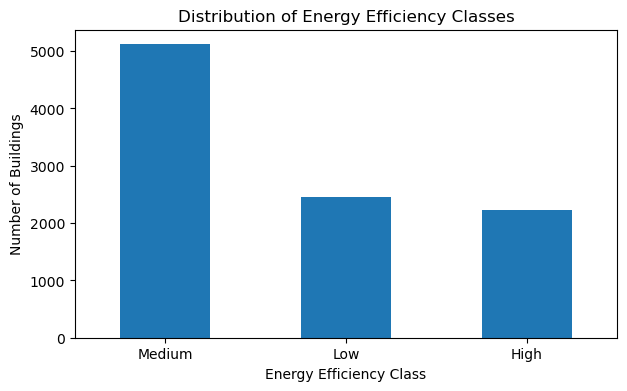

In [39]:
# Visualise the distribution of energy efficiency classes
class_counts = df_clean["EfficiencyClass"].value_counts()

plt.figure(figsize=(7, 4))
class_counts.plot(kind="bar")

plt.title("Distribution of Energy Efficiency Classes")
plt.xlabel("Energy Efficiency Class")
plt.ylabel("Number of Buildings")
plt.xticks(rotation=0)
plt.show()

The chart shows that Medium is the largest group, with 5,118 buildings. Low has 2,455 buildings, and High has 2,222 buildings. This means the dataset is not fully balanced.

In [40]:
# Percentage of energy efficiency classes by county
county_counts = pd.crosstab(df_clean["CountyClean"], df_clean["EfficiencyClass"], normalize="index") * 100

print(county_counts.head())

EfficiencyClass       High        Low     Medium
CountyClean                                     
Carlow           18.584071  15.929204  65.486726
Cavan            30.833333  20.833333  48.333333
Clare            17.948718  30.341880  51.709402
Cork             24.259408  25.220176  50.520416
Donegal          22.457627  12.711864  64.830508


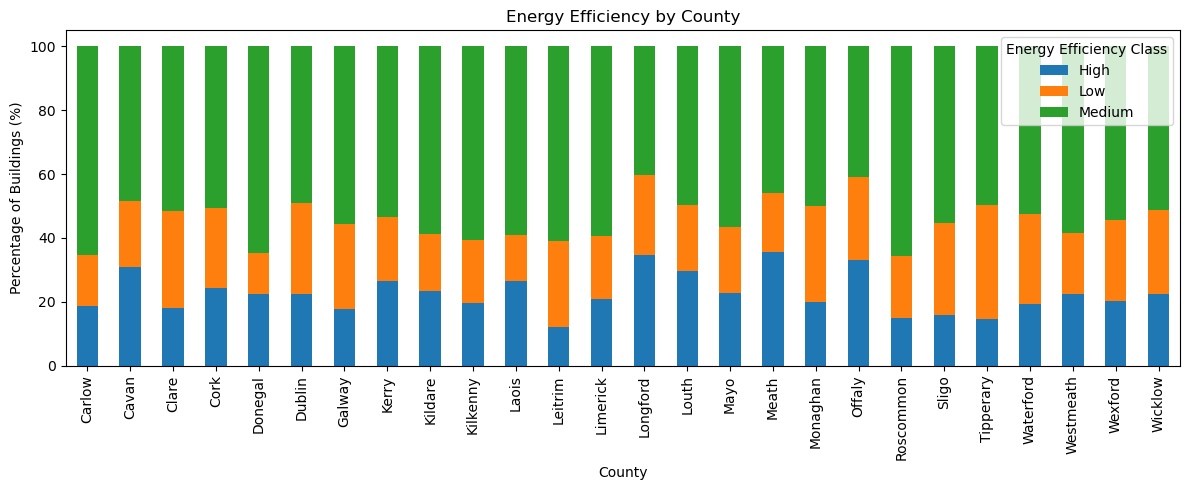

In [41]:
# Visualise energy efficiency by county
county_counts.plot(kind="bar", stacked=True, figsize=(12, 5))

plt.title("Energy Efficiency by County")
plt.xlabel("County")
plt.ylabel("Percentage of Buildings (%)")
plt.legend(title="Energy Efficiency Class")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [42]:
# Top 5 counties with the highest percentage of High ratings
print(county_counts["High"].sort_values(ascending=False).head(5))

CountyClean
Meath       35.483871
Longford    34.782609
Offaly      32.954545
Cavan       30.833333
Louth       29.508197
Name: High, dtype: float64


The results show that Meath (35.48%), Longford (34.78%), Offaly (32.95%), Cavan (30.83%) and Louth (29.51%) have the highest percentages of buildings in the High energy efficiency class in my dataset. Most counties have more buildings in the Medium class. This shows that energy efficiency ratings vary between counties.

In [43]:
# Percentage of energy efficiency classes by Dwelling type
dwelling_counts = pd.crosstab(df_clean["DwellingTypeDescr"], df_clean["EfficiencyClass"], normalize="index") * 100

print(dwelling_counts)

EfficiencyClass              High        Low     Medium
DwellingTypeDescr                                      
Apartment               20.353982  27.433628  52.212389
Detached house          19.000819  25.470925  55.528256
End of terrace house    26.590538  25.938010  47.471452
Ground-floor apartment  20.503597  33.812950  45.683453
House                   25.326910  26.152787  48.520303
Maisonette              36.567164  13.432836  50.000000
Mid-floor apartment     28.127854  15.342466  56.529680
Mid-terrace house       26.782884  28.288431  44.928685
Semi-detached house     17.562380  21.353167  61.084453
Top-floor apartment     20.733104  31.271478  47.995418


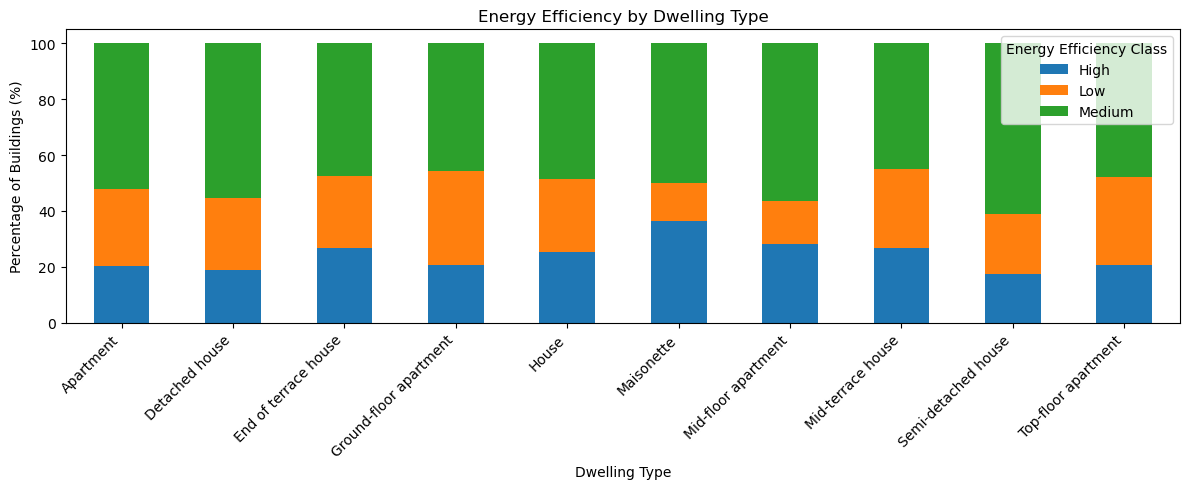

In [44]:
# Visualise energy efficiency by dwelling type
dwelling_counts.plot(kind="bar", stacked=True, figsize=(12, 5))

plt.title("Energy Efficiency by Dwelling Type")
plt.xlabel("Dwelling Type")
plt.ylabel("Percentage of Buildings (%)")
plt.legend(title="Energy Efficiency Class")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

The results show that Maisonettes have the highest percentage of buildings in the High energy efficiency class (36.57%). Mid-floor apartments also have a relatively high percentage (28.13%). Ground-floor apartments have the highest percentage in the Low class (33.81%). Most dwelling types have more buildings in the Medium class. This shows that energy efficiency ratings vary by dwelling type in my dataset.

In [45]:
# Number of buildings by dwelling type
print(df_clean["DwellingTypeDescr"].value_counts())

DwellingTypeDescr
Semi-detached house       2084
House                     1453
Mid-terrace house         1262
Detached house            1221
Mid-floor apartment       1095
Top-floor apartment        873
Ground-floor apartment     834
End of terrace house       613
Apartment                  226
Maisonette                 134
Name: count, dtype: int64


Maisonettes had the highest percentage of High energy efficiency ratings (36.57%), but the sample size was small (134 buildings).

## 4. Model Preparation

I used 10 building features to predict energy efficiency. The target variable is EfficiencyClass, which has three groups: High, Medium and Low.

In [46]:
# Select input features
X = df_clean[["CountyClean",
        "DwellingTypeDescr",
        "Year_of_Construction",
        "GroundFloorArea(sq m)",
        "NoStoreys",
        "UValueWall",
        "UValueRoof",
        "UValueWindow",
        "MainSpaceHeatingFuel",
        "HSMainSystemEfficiency"]]

# Select target
y = df_clean["EfficiencyClass"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (9795, 10)
y shape: (9795,)


In [47]:
# Split data into training (25%) and testing (75%) sets
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.25, random_state=42)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (2448, 10)
Testing: (7347, 10)


In [48]:
# Check categorical features
X_train.select_dtypes(include="object").head()

,CountyClean,DwellingTypeDescr,MainSpaceHeatingFuel
11281,Cork,Ground-floor apartment,Electricity
38902,Cork,Detached house,Heating Oil
15118,Kildare,Mid-terrace house,Mains Gas
46192,Dublin,Semi-detached house,Heating Oil
454,Cork,Semi-detached house,Heating Oil


In [49]:
# Check categorical columns
categorical_cols = X_train.select_dtypes(include="object").columns

print(categorical_cols)

Index(['CountyClean', 'DwellingTypeDescr', 'MainSpaceHeatingFuel'], dtype='object')


In [50]:
# Encode categorical features
X_train_encoded = pd.get_dummies(X_train, columns=categorical_cols, dtype=int)

X_test_encoded = pd.get_dummies(X_test, columns=categorical_cols, dtype=int)

# Make sure train and test have the same columns
X_test_encoded = X_test_encoded.reindex(columns=X_train_encoded.columns, fill_value=0)

print("Training:", X_train_encoded.shape)
print("Testing:", X_test_encoded.shape)

Training: (2448, 57)
Testing: (7347, 57)


In [51]:
# Feature Scaling
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_encoded)
X_test_scaled = scaler.transform(X_test_encoded)

print("Training:", X_train_scaled.shape)
print("Testing:", X_test_scaled.shape)

Training: (2448, 57)
Testing: (7347, 57)


## 5. Model Training and Testing

I used two machine learning models: Support Vector Machine (SVM) and Random Forest. I trained both models and tested how well they predict energy efficiency.

In [52]:
# Train SVM model
from sklearn.svm import SVC

svm_model = SVC()

svm_model.fit(X_train_scaled, y_train)

SVC()

In [53]:
# Predict using SVM
y_pred_svm = svm_model.predict(X_test_scaled)

# Check accuracy
from sklearn.metrics import accuracy_score

svm_accuracy = accuracy_score(y_test, y_pred_svm)

print("SVM Accuracy:", svm_accuracy)

SVM Accuracy: 0.7912072954947598


In [54]:
# Train Random Forest model
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(random_state=42)
rf.fit(X_train_encoded, y_train)

RandomForestClassifier(random_state=42)

In [55]:
# Random Forest prediction
y_pred_rf = rf.predict(X_test_encoded)

# Check accuracy
rf_accuracy = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", rf_accuracy)

Random Forest Accuracy: 0.8344902681366544


In [56]:
# Random Forest training accuracy
rf_train_pred = rf.predict(X_train_encoded)

rf_train_accuracy = accuracy_score(y_train, rf_train_pred)

print("Training Accuracy:", rf_train_accuracy)
print("Testing Accuracy:", rf_accuracy)

Training Accuracy: 0.9987745098039216
Testing Accuracy: 0.8344902681366544


In [57]:
# SVM training accuracy
svm_train_pred = svm_model.predict(X_train_scaled)

svm_train_accuracy = accuracy_score(y_train, svm_train_pred)

print("Training Accuracy:", svm_train_accuracy)
print("Testing Accuracy:", svm_accuracy)

Training Accuracy: 0.8619281045751634
Testing Accuracy: 0.7912072954947598


### Confusion Matrix (25% Training Data)

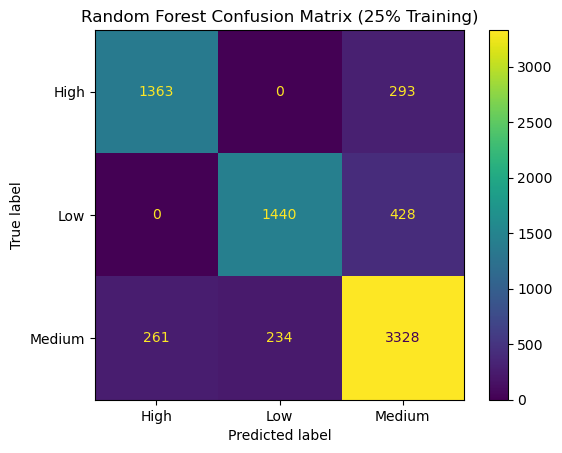

In [58]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Predict the test data
y_pred_rf = rf.predict(X_test_encoded)

# Create and display the confusion matrix
cm_rf = confusion_matrix(y_test, y_pred_rf, labels=rf.classes_)

disp = ConfusionMatrixDisplay(confusion_matrix=cm_rf,display_labels=rf.classes_)

disp.plot()
plt.title("Random Forest Confusion Matrix (25% Training)")
plt.show()

The confusion matrix shows that Random Forest predicted the Medium class most accurately (87.05%). The High class had 82.31% correct predictions, while the Low class had 77.09%. Most incorrect predictions were classified as Medium.

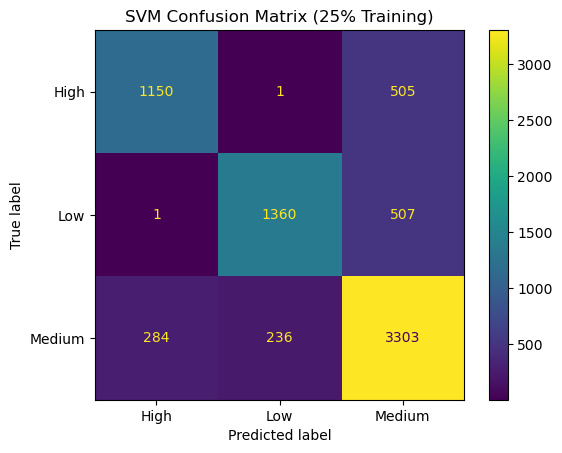

In [59]:
# SVM prediction
y_pred_svm = svm_model.predict(X_test_scaled)

# SVM confusion matrix
cm_svm = confusion_matrix(y_test, y_pred_svm, labels=svm_model.classes_)

disp = ConfusionMatrixDisplay(confusion_matrix=cm_svm,display_labels=svm_model.classes_)

disp.plot()
plt.title("SVM Confusion Matrix (25% Training)")
plt.show()

The confusion matrices show that Random Forest performed better than SVM in all three energy efficiency classes. The biggest difference was in the High class, where Random Forest correctly predicted 82.31% and SVM predicted 69.44%.

Both models performed best in the Medium class. They also made most of their mistakes by predicting High or Low buildings as Medium.

Overall, Random Forest gave better results, but both models had some difficulty distinguishing Medium buildings from High and Low buildings.

### Training with 15% of the Data

I used 15% of the data for training and 85% for testing. I wanted to see how the models work with less training data.

In [60]:
# 15% training split
X_train_15, X_test_15, y_train_15, y_test_15 = train_test_split(X, y,train_size=0.15,random_state=42)

print("Training:", X_train_15.shape)
print("Testing:", X_test_15.shape)

Training: (1469, 10)
Testing: (8326, 10)


In [61]:
# Encode categorical features for 15% split
X_train_15_encoded = pd.get_dummies(X_train_15, columns=categorical_cols, dtype=int)
X_test_15_encoded = pd.get_dummies(X_test_15, columns=categorical_cols, dtype=int)

# Make sure train and test have the same columns
X_test_15_encoded = X_test_15_encoded.reindex(columns=X_train_15_encoded.columns, fill_value=0)

print("Training:", X_train_15_encoded.shape)
print("Testing:", X_test_15_encoded.shape)

Training: (1469, 56)
Testing: (8326, 56)


In [62]:
# Feature Scaling for 15% split
scaler_15 = StandardScaler()

X_train_15_scaled = scaler_15.fit_transform(X_train_15_encoded)
X_test_15_scaled = scaler_15.transform(X_test_15_encoded)

print("Training:", X_train_15_scaled.shape)
print("Testing:", X_test_15_scaled.shape)

Training: (1469, 56)
Testing: (8326, 56)


In [63]:
# Train SVM model for 15% split
svm_15 = SVC()

svm_15.fit(X_train_15_scaled, y_train_15)

SVC()

In [64]:
# SVM prediction for 15% split
y_pred_svm_15 = svm_15.predict(X_test_15_scaled)

svm_accuracy_15 = accuracy_score(y_test_15, y_pred_svm_15)

print("SVM Accuracy (15%):", svm_accuracy_15)

SVM Accuracy (15%): 0.7617103050684603


In [65]:
# SVM Training Accuracy for 15% split
svm_train_pred_15 = svm_15.predict(X_train_15_scaled)
svm_train_accuracy_15 = accuracy_score(y_train_15, svm_train_pred_15)

print("SVM Training Accuracy (15%):", svm_train_accuracy_15)

SVM Training Accuracy (15%): 0.8420694349897889


In [66]:
# Train Random Forest for 15% split
rf_15 = RandomForestClassifier(random_state=42)

rf_15.fit(X_train_15_encoded, y_train_15)

RandomForestClassifier(random_state=42)

In [67]:
# Random Forest Test Accuracy (15%)
y_pred_rf_15 = rf_15.predict(X_test_15_encoded)

rf_accuracy_15 = accuracy_score(y_test_15, y_pred_rf_15)

print("RF Accuracy (15%):", rf_accuracy_15)

RF Accuracy (15%): 0.8265673792937785


In [68]:
# Random Forest Training Accuracy (15%)
rf_train_pred_15 = rf_15.predict(X_train_15_encoded)
rf_train_accuracy_15 = accuracy_score(y_train_15, rf_train_pred_15)

print("RF Training Accuracy (15%):", rf_train_accuracy_15)

RF Training Accuracy (15%): 0.9993192648059904


Training with 5% of the Data

I used 5% of the data for training and 95% for testing. This helps me understand how the models perform with a very small training dataset.

In [69]:
# 5% training split
X_train_5, X_test_5, y_train_5, y_test_5 = train_test_split(X, y,train_size=0.05,random_state=42)

print("Training:", X_train_5.shape)
print("Testing:", X_test_5.shape)

Training: (489, 10)
Testing: (9306, 10)


In [70]:
# Encode categorical features for 5% split
X_train_5_encoded = pd.get_dummies(X_train_5, columns=categorical_cols, dtype=int)
X_test_5_encoded = pd.get_dummies(X_test_5, columns=categorical_cols, dtype=int)

# Make sure train and test have the same columns
X_test_5_encoded = X_test_5_encoded.reindex(columns=X_train_5_encoded.columns, fill_value=0)

print("Training:", X_train_5_encoded.shape)
print("Testing:", X_test_5_encoded.shape)

Training: (489, 52)
Testing: (9306, 52)


In [71]:
# Feature Scaling for 5% split
scaler_5 = StandardScaler()

X_train_5_scaled = scaler_5.fit_transform(X_train_5_encoded)
X_test_5_scaled = scaler_5.transform(X_test_5_encoded)

print("Training:", X_train_5_scaled.shape)
print("Testing:", X_test_5_scaled.shape)

Training: (489, 52)
Testing: (9306, 52)


In [72]:
# Train SVM model for 5% split
svm_5 = SVC()

svm_5.fit(X_train_5_scaled, y_train_5)

SVC()

In [73]:
# SVM prediction for 5% split
y_pred_svm_5 = svm_5.predict(X_test_5_scaled)

svm_accuracy_5 = accuracy_score(y_test_5, y_pred_svm_5)

print("SVM Accuracy (5%):", svm_accuracy_5)

SVM Accuracy (5%): 0.6903073286052009


In [74]:
svm_train_pred_5 = svm_5.predict(X_train_5_scaled)
svm_train_accuracy_5 = accuracy_score(y_train_5, svm_train_pred_5)

print("SVM Training Accuracy (5%):", svm_train_accuracy_5)

SVM Training Accuracy (5%): 0.8588957055214724


In [75]:
# Train Random Forest for 5% split
rf_5 = RandomForestClassifier(random_state=42)

rf_5.fit(X_train_5_encoded, y_train_5)

RandomForestClassifier(random_state=42)

In [76]:
# Random Forest Test Accuracy (5%)
y_pred_rf_5 = rf_5.predict(X_test_5_encoded)

rf_accuracy_5 = accuracy_score(y_test_5, y_pred_rf_5)

print("RF Accuracy (5%):", rf_accuracy_5)

RF Accuracy (5%): 0.8036750483558994


In [77]:
rf_train_pred_5 = rf_5.predict(X_train_5_encoded)
rf_train_accuracy_5 = accuracy_score(y_train_5, rf_train_pred_5)

In [78]:
print("RF Training Accuracy (5%):", rf_train_accuracy_5)
print("RF Testing Accuracy (5%):", rf_accuracy_5)

RF Training Accuracy (5%): 1.0
RF Testing Accuracy (5%): 0.8036750483558994


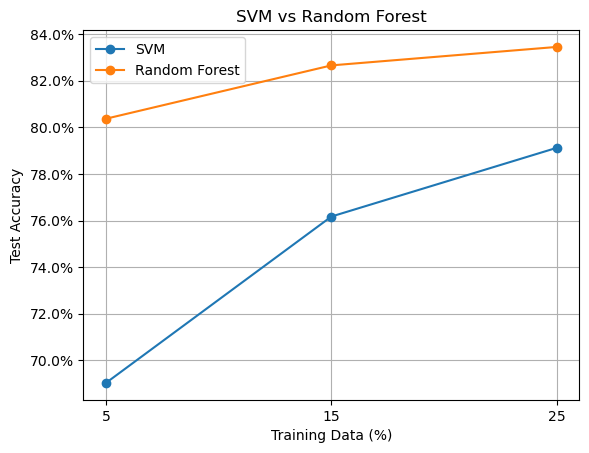

In [79]:
import matplotlib.pyplot as plt

training_sizes = [5, 15, 25]

svm_scores = [svm_accuracy_5, svm_accuracy_15, svm_accuracy]
rf_scores = [rf_accuracy_5, rf_accuracy_15, rf_accuracy]

plt.plot(training_sizes, svm_scores, marker='o', label='SVM')
plt.plot(training_sizes, rf_scores, marker='o', label='Random Forest')

plt.xlabel('Training Data (%)')
plt.ylabel('Test Accuracy')
plt.title('SVM vs Random Forest')
plt.xticks(training_sizes)
plt.legend()
plt.grid(True)

from matplotlib.ticker import PercentFormatter
plt.gca().yaxis.set_major_formatter(PercentFormatter(1))
plt.show()

## 6. Cross-Validation

Cross-validation is used to evaluate how consistently the models perform on different subsets of the training data.

In [80]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline

categorical_cols = X_train.select_dtypes(include="object").columns.tolist()
numeric_cols = X_train.select_dtypes(exclude="object").columns.tolist()

print("Categorical:", categorical_cols)
print("Numeric:", numeric_cols)

Categorical: ['CountyClean', 'DwellingTypeDescr', 'MainSpaceHeatingFuel']
Numeric: ['Year_of_Construction', 'GroundFloorArea(sq m)', 'NoStoreys', 'UValueWall', 'UValueRoof', 'UValueWindow', 'HSMainSystemEfficiency']


In [81]:
data_prep = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),("num", StandardScaler(), numeric_cols)])

In [82]:
# SVM pipeline for Cross-Validation
svm_cv = make_pipeline(data_prep, SVC())

print(svm_cv)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['CountyClean',
                                                   'DwellingTypeDescr',
                                                   'MainSpaceHeatingFuel']),
                                                 ('num', StandardScaler(),
                                                  ['Year_of_Construction',
                                                   'GroundFloorArea(sq m)',
                                                   'NoStoreys', 'UValueWall',
                                                   'UValueRoof', 'UValueWindow',
                                                   'HSMainSystemEfficiency'])])),
                ('svc', SVC())])


In [83]:
from sklearn.model_selection import cross_val_score

svm_cv_scores = cross_val_score(svm_cv, X_train, y_train, cv=5)

print("SVM CV Scores:", svm_cv_scores)
print("SVM Mean CV Accuracy:", svm_cv_scores.mean())

SVM CV Scores: [0.85306122 0.81428571 0.85102041 0.8200409  0.83231084]
SVM Mean CV Accuracy: 0.8341438170360169


In [84]:
# Random Forest pipeline
rf_pipeline = make_pipeline(data_prep, RandomForestClassifier(random_state=42))

print(rf_pipeline)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['CountyClean',
                                                   'DwellingTypeDescr',
                                                   'MainSpaceHeatingFuel']),
                                                 ('num', StandardScaler(),
                                                  ['Year_of_Construction',
                                                   'GroundFloorArea(sq m)',
                                                   'NoStoreys', 'UValueWall',
                                                   'UValueRoof', 'UValueWindow',
                                                   'HSMainSystemEfficiency'])])),
                ('randomforestclassifier',
                 RandomForestClassifier(random_state=42))])


In [85]:
rf_scores_5fold = cross_val_score(rf_pipeline, X_train, y_train, cv=5)

print("RF CV Scores:", rf_scores_5fold)
print("RF Mean CV Accuracy:", rf_scores_5fold.mean())

RF CV Scores: [0.86530612 0.83265306 0.84693878 0.82617587 0.80981595]
RF Mean CV Accuracy: 0.8361779558449147


# Cross-Validation Results

I used 5-fold cross-validation to check the performance of both models.

SVM: Average accuracy was 83.41%.

Random Forest: Average accuracy was 83.62%.

Both models showed similar results. Random Forest had a slightly higher average accuracy.

Cross-validation helps check how consistently the models perform on different parts of the training data.

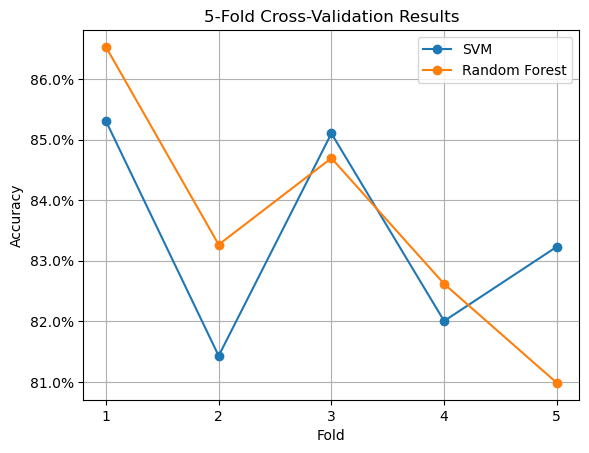

In [86]:
folds = [1, 2, 3, 4, 5]

plt.plot(folds, svm_cv_scores, marker='o', label='SVM')
plt.plot(folds, rf_scores_5fold, marker='o', label='Random Forest')

plt.xlabel('Fold')
plt.ylabel('Accuracy')
plt.title('5-Fold Cross-Validation Results')
plt.xticks(folds)
plt.legend()
plt.grid(True)
plt.gca().yaxis.set_major_formatter(PercentFormatter(1))
plt.show()

## 7. Hyperparameter Tuning

Hyperparameter tuning is used to find better settings for a machine learning model and improve its performance.

In [87]:
from sklearn.model_selection import GridSearchCV

In [88]:
param_grid = {'randomforestclassifier__n_estimators': [50, 100],'randomforestclassifier__max_depth': [5, 10, None]}

In [89]:
grid_search = GridSearchCV(rf_pipeline, param_grid, cv=5, scoring='accuracy')

In [90]:
grid_search.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('columntransformer',
                                        ColumnTransformer(transformers=[('cat',
                                                                         OneHotEncoder(handle_unknown='ignore'),
                                                                         ['CountyClean',
                                                                          'DwellingTypeDescr',
                                                                          'MainSpaceHeatingFuel']),
                                                                        ('num',
                                                                         StandardScaler(),
                                                                         ['Year_of_Construction',
                                                                          'GroundFloorArea(sq '
                                                                          'm)',
                                                                          'NoStoreys',
                                                                          'UValueWall',
                                                                          'UValueRoof',
                                                                          'UValueWindow',
                                                                          'HSMainSystemEfficiency'])])),
                                       ('randomforestclassifier',
                                        RandomForestClassifier(random_state=42))]),
             param_grid={'randomforestclassifier__max_depth': [5, 10, None],
                         'randomforestclassifier__n_estimators': [50, 100]},
             scoring='accuracy')

In [91]:
print("Best Parameters:", grid_search.best_params_)
print("Best CV Accuracy:", grid_search.best_score_)

Best Parameters: {'randomforestclassifier__max_depth': None, 'randomforestclassifier__n_estimators': 100}
Best CV Accuracy: 0.8361779558449147


In [92]:
best_rf = grid_search.best_estimator_

y_pred_tuned = best_rf.predict(X_test)

tuned_accuracy = accuracy_score(y_test, y_pred_tuned)

print("Tuned RF Test Accuracy:", tuned_accuracy)

Tuned RF Test Accuracy: 0.8383013474887709


In [93]:
rf_pipeline.fit(X_train, y_train)

original_pred = rf_pipeline.predict(X_test)

original_accuracy = accuracy_score(y_test, original_pred)

print("Original RF Accuracy:", original_accuracy)
print("Tuned RF Accuracy:", tuned_accuracy)

Original RF Accuracy: 0.8383013474887709
Tuned RF Accuracy: 0.8383013474887709


## 8. Feature Importance
Feature importance helps identify which features are most useful for predicting energy efficiency.

In [94]:
importance = best_rf.named_steps['randomforestclassifier']

print(importance.feature_importances_)

[1.76775342e-03 2.04021215e-03 2.66689357e-03 9.12777088e-03
 2.83729002e-03 1.18724858e-02 4.04272468e-03 3.10113369e-03
 4.39666247e-03 3.71047088e-03 1.07859058e-03 6.15409849e-04
 4.51386635e-03 1.26788046e-03 3.86790151e-03 2.00331204e-03
 3.47375364e-03 1.35691868e-03 1.64892133e-03 1.03347003e-03
 2.87539978e-03 2.87819633e-03 3.01996613e-03 2.30291703e-03
 2.09098054e-03 3.20785281e-03 2.82817816e-03 6.24331037e-03
 5.54194736e-03 8.39808610e-03 8.10666869e-03 1.83162571e-03
 1.72989855e-02 7.32793144e-03 7.92842188e-03 6.31179425e-03
 2.19008171e-05 5.08217949e-04 1.53191070e-03 2.28729272e-02
 1.39560467e-04 1.24065449e-04 7.95221401e-03 7.14801427e-04
 1.72412198e-02 6.87496898e-07 6.32962629e-05 2.50645473e-03
 2.10770840e-04 2.81205815e-04 1.56587695e-01 1.03458358e-01
 1.93850038e-02 1.87516066e-01 1.01398275e-01 1.18070035e-01
 1.04799650e-01]


In [95]:
names = best_rf.named_steps['columntransformer'].get_feature_names_out()

print(names)

['cat__CountyClean_Carlow' 'cat__CountyClean_Cavan'
 'cat__CountyClean_Clare' 'cat__CountyClean_Cork'
 'cat__CountyClean_Donegal' 'cat__CountyClean_Dublin'
 'cat__CountyClean_Galway' 'cat__CountyClean_Kerry'
 'cat__CountyClean_Kildare' 'cat__CountyClean_Kilkenny'
 'cat__CountyClean_Laois' 'cat__CountyClean_Leitrim'
 'cat__CountyClean_Limerick' 'cat__CountyClean_Longford'
 'cat__CountyClean_Louth' 'cat__CountyClean_Mayo' 'cat__CountyClean_Meath'
 'cat__CountyClean_Monaghan' 'cat__CountyClean_Offaly'
 'cat__CountyClean_Roscommon' 'cat__CountyClean_Sligo'
 'cat__CountyClean_Tipperary' 'cat__CountyClean_Waterford'
 'cat__CountyClean_Westmeath' 'cat__CountyClean_Wexford'
 'cat__CountyClean_Wicklow' 'cat__DwellingTypeDescr_Apartment'
 'cat__DwellingTypeDescr_Detached house'
 'cat__DwellingTypeDescr_End of terrace house'
 'cat__DwellingTypeDescr_Ground-floor apartment'
 'cat__DwellingTypeDescr_House' 'cat__DwellingTypeDescr_Maisonette'
 'cat__DwellingTypeDescr_Mid-floor apartment'
 'cat__Dwel

In [96]:
# Check feature names and importance values
print(len(names))
print(len(importance.feature_importances_))

57
57


In [97]:
feature_table = pd.DataFrame({'Feature': names,'Importance': importance.feature_importances_})

print(feature_table.head())

                    Feature  Importance
0   cat__CountyClean_Carlow    0.001768
1    cat__CountyClean_Cavan    0.002040
2    cat__CountyClean_Clare    0.002667
3     cat__CountyClean_Cork    0.009128
4  cat__CountyClean_Donegal    0.002837


In [98]:
best10 = feature_table.sort_values(by='Importance', ascending=False).head(10)

print(best10)

                                              Feature  Importance
53                                    num__UValueWall    0.187516
50                          num__Year_of_Construction    0.156588
55                                  num__UValueWindow    0.118070
56                        num__HSMainSystemEfficiency    0.104800
51                         num__GroundFloorArea(sq m)    0.103458
54                                    num__UValueRoof    0.101398
39  cat__MainSpaceHeatingFuel_Electricity         ...    0.022873
52                                     num__NoStoreys    0.019385
32         cat__DwellingTypeDescr_Mid-floor apartment    0.017299
44  cat__MainSpaceHeatingFuel_Mains Gas           ...    0.017241


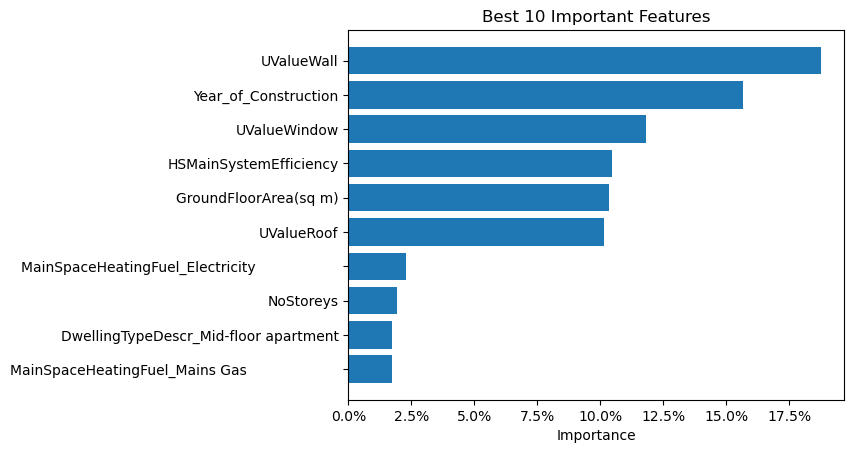

In [99]:
clean_names = best10['Feature'].str.replace('num__', '').str.replace('cat__', '')

plt.barh(clean_names, best10['Importance'])

plt.xlabel('Importance')
plt.title('Best 10 Important Features')
plt.gca().invert_yaxis()
plt.gca().xaxis.set_major_formatter(PercentFormatter(1))
plt.show()

## 9. Overfitting and Underfitting
Random Forest performed better than SVM on the testing data for all three training sizes (5%, 15%, and 25%). Both models achieved their best testing accuracy with 25% training data.

At 25% training data, Random Forest achieved 99.88% training accuracy and 83.45% testing accuracy. The difference was 16.43 percentage points. In comparison, SVM had a smaller difference of 7.07 percentage points.

This shows that Random Forest has stronger signs of overfitting, even though it achieved better testing accuracy. I think reducing overfitting is necessary because the training and testing accuracy gap is more than twice as large as SVM's.

There is no clear evidence of underfitting in these results because both models achieved relatively high training accuracy.